In [ ]:
#Data Acquisition and Compilation
#Load Data Files
import pandas as pd
true_df = pd.read_csv("True.csv", on_bad_lines='skip', engine='python')
fake_df = pd.read_csv("Fake.csv", on_bad_lines='skip', engine='python')


#Assign explicit binary labels
true_df['class'] = 1
fake_df['class'] = 0
#Merge dataset
combined_df = pd.concat([true_df, fake_df], axis=0)
combined_df.shape

shuffled_df = combined_df.sample(frac=1, random_state=42).reset_index(drop=True)
shuffled_df.head()

shuffled_df.to_csv("clean_news_data.csv", index=False)
print("Masterpiece Saved Successfully!")

#TEXT PREPROCESSING CORRECTION LAYER
import re
import string
def clean_text(text):
  text = text.lower()
  text = re.sub(r'https?://\S+|www\.\S+', '', text)
  text = re.sub(f"[{re.escape(string.punctuation)}]", '', text)
  return text
  #Apply textual uniform scrubbing
shuffled_df['text'] = shuffled_df['text'].apply(clean_text)
shuffled_df['text'].head()

shuffled_df.to_csv("clean_news_data.csv", index=False)
print("All code and clean text saved!")

Masterpiece Saved Successfully!
All code and clean text saved!


/tmp/ipykernel_726/3443176986.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='class', data=shuffled_df, order=[0, 1], palette=['#e74c3c', '#2ecc71'])


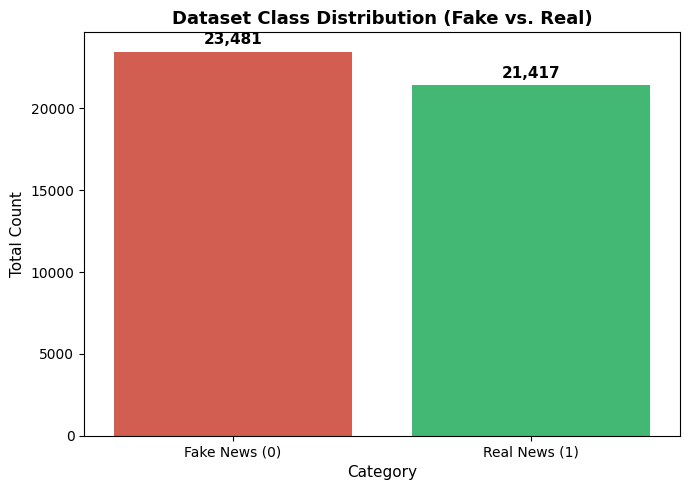

In [ ]:
# DATASET VISUALIZATION (EXPACT COUNT MATCHING DOCUMENT)

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

# Force explicit order [0, 1] so Fake (0) is always first, True (1) is second
ax = sns.countplot(x='class', data=shuffled_df, order=[0, 1], palette=['#e74c3c', '#2ecc71'])

plt.xticks(ticks=[0, 1], labels=['Fake News (0)', 'Real News (1)'])
plt.title('Dataset Class Distribution (Fake vs. Real)', fontsize=13, fontweight='bold')
plt.xlabel('Category', fontsize=11)
plt.ylabel('Total Count', fontsize=11)

# Annotate exact numerical counts on top of each bar
for p in ax.patches:
    height = int(p.get_height())
    ax.annotate(f'{height:,}',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom',
                fontsize=11, fontweight='bold',
                xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.savefig('class_distribution.png', dpi=300)
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
X = shuffled_df['text']
y = shuffled_df['class']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
vectorizer = TfidfVectorizer(max_features=5000)
X_train_vectorised = vectorizer.fit_transform(X_train)
X_test_vectorised = vectorizer.transform(X_test)
print("Training data shape:", X_train_vectorised.shape)

Training data shape: (35918, 5000)


Training KNN...
KNN Final Accuracy: 0.7630

KNN Classification Report:
               precision    recall  f1-score   support

           0       0.71      0.93      0.80      4669
           1       0.89      0.58      0.70      4311

    accuracy                           0.76      8980
   macro avg       0.80      0.76      0.75      8980
weighted avg       0.79      0.76      0.75      8980

--------------------------------------------------
Training Logistic Regression...
Logistic Regression Final Accuracy: 0.9860

Logistic Regression Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.98      0.99      4669
           1       0.98      0.99      0.99      4311

    accuracy                           0.99      8980
   macro avg       0.99      0.99      0.99      8980
weighted avg       0.99      0.99      0.99      8980

--------------------------------------------------
Training Random Forest...
Random Forest Final Accura

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


Neural Network Final Accuracy: 0.9915

Neural Network Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.99      0.99      4669
           1       0.99      0.99      0.99      4311

    accuracy                           0.99      8980
   macro avg       0.99      0.99      0.99      8980
weighted avg       0.99      0.99      0.99      8980

--------------------------------------------------


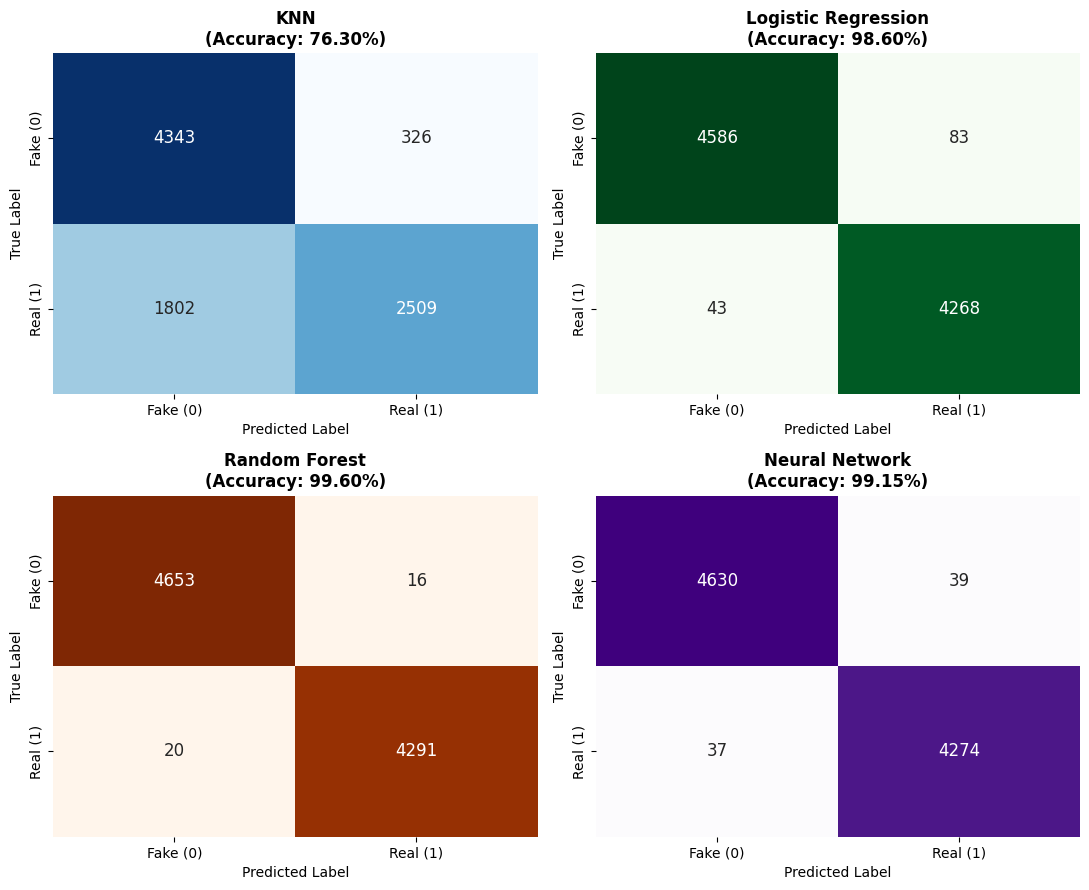

In [ ]:
# MACHINE LEARNING PIPELINE EXECUTION & 2x2 CONFUSION MATRIX GRID
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_recall_fscore_support
import matplotlib.pyplot as plt
import seaborn as sns

models = {
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Neural Network": MLPClassifier(hidden_layer_sizes=(50, 25), max_iter=20, random_state=42)
}

results_list = []
predictions = {}

# Train models and collect predictions
for name, model in models.items():
    try:
        print(f"Training {name}...")
        model.fit(X_train_vectorised, y_train)
        preds = model.predict(X_test_vectorised)
        predictions[name] = preds

        # Calculate overall accuracy
        acc = accuracy_score(y_test, preds)

        # Precision, Recall, and F1 specifically for Class 1 (matches document)
        prec, rec, f1, _ = precision_recall_fscore_support(y_test, preds, pos_label=1, average='binary')

        results_list.append({
            'Model': name,
            'Accuracy': acc,
            'Precision': prec,
            'Recall': rec,
            'F1-Score': f1
        })

        print(f"{name} Final Accuracy: {acc:.4f}")
        print(f"\n{name} Classification Report:\n", classification_report(y_test, preds))
        print("-" * 50)

    except Exception as e:
        print(f"Error training {name}: {e}")
        print("-" * 50)

# VISUALIZATION: 2x2 GRID OF CONFUSION MATRICES

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
axes = axes.flatten()

cmaps = ['Blues', 'Greens', 'Oranges', 'Purples']

for idx, (name, y_pred) in enumerate(predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    acc = next(item['Accuracy'] for item in results_list if item['Model'] == name)

    sns.heatmap(cm, annot=True, fmt='d', cmap=cmaps[idx], ax=axes[idx], cbar=False, annot_kws={"size": 12})
    axes[idx].set_title(f'{name}\n(Accuracy: {acc*100:.2f}%)', fontweight='bold', fontsize=12)
    axes[idx].set_xlabel('Predicted Label', fontsize=10)
    axes[idx].set_ylabel('True Label', fontsize=10)
    axes[idx].set_xticklabels(['Fake (0)', 'Real (1)'])
    axes[idx].set_yticklabels(['Fake (0)', 'Real (1)'])

plt.tight_layout()
plt.savefig('confusion_matrices_2x2_grid.png', dpi=300)
plt.show()

In [ ]:
# SAVE THE TRAINED MODEL AND TF-IDF VECTORIZER FOR DEPLOYMENT

import os
import joblib
import sklearn

os.makedirs("model", exist_ok=True)

# Select the best-performing model from this experiment.
best_model = models["Random Forest"]

joblib.dump(best_model, "model/fake_news_model.pkl")
joblib.dump(vectorizer, "model/tfidf_vectorizer.pkl")

print("Model and TF-IDF vectorizer saved successfully.")
print("Scikit-learn version:", sklearn.__version__)
print("Upload the complete 'model' folder to your GitHub repository.")


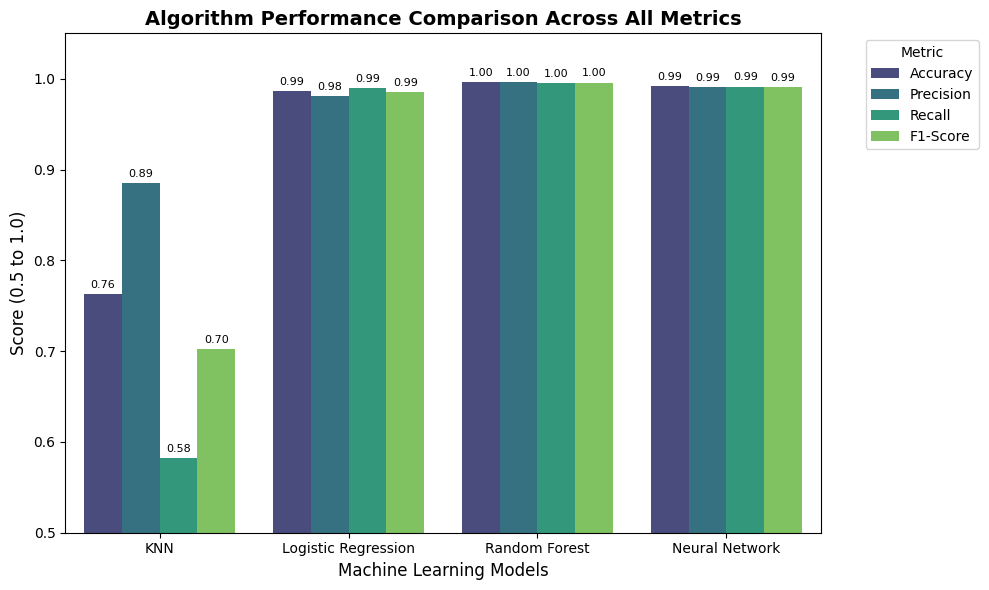

In [ ]:
# MODEL PERFORMANCE COMPARISON VISUALIZATION
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

metrics_df = pd.DataFrame(results_list)

# Reshape data for plotting
melted_df = pd.melt(metrics_df, id_vars=['Model'], var_name='Metric', value_name='Score')

# Grouped bar chart comparing Accuracy, Precision, Recall, and F1-Score
plt.figure(figsize=(10, 6))
chart = sns.barplot(x='Model', y='Score', hue='Metric', data=melted_df, palette='viridis')
plt.ylim(0.5, 1.05)
plt.title('Algorithm Performance Comparison Across All Metrics', fontsize=14, fontweight='bold')
plt.xlabel('Machine Learning Models', fontsize=12)
plt.ylabel('Score (0.5 to 1.0)', fontsize=12)
plt.legend(title='Metric', bbox_to_anchor=(1.05, 1), loc='upper left')

# Display values above bars
for p in chart.patches:
    height = p.get_height()
    if height > 0:
        chart.annotate(f'{height:.2f}',
                       (p.get_x() + p.get_width() / 2., height),
                       ha='center', va='bottom',
                       fontsize=8, xytext=(0, 3),
                       textcoords='offset points')

plt.tight_layout()
plt.savefig('all_metrics_comparison.png', dpi=300)
plt.show()

In [ ]:
# PREDICTION USING THE BEST-PERFORMING TRAINED MODEL

# Random Forest achieved the highest accuracy in the reported experiment.
best_model = models["Random Forest"]

def predict_news(news_text):
    cleaned_text = clean_text(news_text)
    vectorized_text = vectorizer.transform([cleaned_text])
    prediction = best_model.predict(vectorized_text)[0]

    if prediction == 1:
        return "REAL NEWS (Class 1)"
    else:
        return "FAKE NEWS (Class 0)"

my_news = (
    "Washington (Reuters) - The US Senate voted unanimously on Tuesday "
    "to declare that the moon is made entirely of green cheese, officials confirmed."
)

result = predict_news(my_news)
print(f"News Text: '{my_news}'")
print(f"Model Prediction: {result}")

print("\nNote: This is a text classifier, not an independent fact-checking system.")


News Text: 'Washington (Reuters) - The US Senate voted unanimously on Tuesday todeclare that the moon is made entirely of green cheese, officials confirmed.'
AI Prediction: 📰 TRUE NEWS (Verified/Reliable)


## Deployment preparation

After running all training cells, run the model-export cell to create:
- `model/fake_news_model.pkl`
- `model/tfidf_vectorizer.pkl`

Upload these two files, `app.py`, and `requirements.txt` to your GitHub repository.
The Streamlit app uses the same text-cleaning steps and the saved Random Forest model.
